This test is on
    1. i.i.d. rayleigh fading channel
    2. 4*4 MIMO channel
    3. 1000 symbols per channel
    4. total of 1000 channels


In [1]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
# change the dir
!ls
# just for checking that the current folder is correct

fatal: destination path 'EE_MIMO_PROJECT' already exists and is not an empty directory.
/content/EE_MIMO_PROJECT
NYCU_scene  src


In [2]:
import sys
from pathlib import Path

# cwd = Path.cwd()
# repo_root = next(path for path in (cwd, *cwd.parents) if (path / "src/models/MAP.py").is_file())
# sys.path.insert(0, str(repo_root))

# import models
from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": partialMAP()
}

In [3]:
# mimo settings
import torch
from src.channel.rayleighfading import rayleighfading
BLOCKS = 100000
SYMBOLS_PER_CHANNEL = 1
# total of (SYMBOLS_PER_CHANNEL * BLOCKS) symbols are transmitted
NT = 4
NR = 4
SNR_DB = list(range(0, 22, 2))

def generateChannel(NR, NT):
    return rayleighfading(NR=NR, NT=NT)

qpsk = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
gray = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])

In [4]:
# channel simulation
for detector in models.values():
    detector.updatePossibleTXSymbols(qpsk, gray)

errors = torch.zeros((len(SNR_DB), len(models)), dtype=torch.long)
bits_per_snr = gray.shape[1] * NT * SYMBOLS_PER_CHANNEL * BLOCKS

for i in range(BLOCKS):
    if (i % 10 == 0):
        print(f"currently running block: {i} to {i+10}")
    CSI = generateChannel(NT=NT, NR=NR).to(qpsk.dtype)
    tx_idx = torch.randint(len(qpsk), (NT, SYMBOLS_PER_CHANNEL))
    tx_bits = gray[tx_idx]
    y_clean = CSI @ qpsk[tx_idx]
    noise_base = torch.randn_like(y_clean)

    for detector in models.values():
        detector.updateCSI(CSI)

    for i, snr in enumerate(SNR_DB):
        n0 = 10.0 ** (-snr / 10)
        received = (y_clean + n0**0.5 * noise_base).T
        for j, detector in enumerate(models.values()):
            detector.updateNoiseVar(n0)
            detected_bits = detector.detectSequence(received)
            errors[i, j] += (detected_bits != tx_bits).count_nonzero()

ber = errors.double() / bits_per_snr
print(f"{bits_per_snr:,} bits per SNR")
print("SNR (dB)   " + "  ".join(f"{name:>12}" for name in models))
for snr, row in zip(SNR_DB, ber):
    print(f"{snr:8g}   " + "  ".join(f"{value:12.4g}" for value in row))

currently running block:  0
currently running block:  1
currently running block:  2
currently running block:  3
currently running block:  4
currently running block:  5
currently running block:  6
currently running block:  7
currently running block:  8
currently running block:  9
currently running block:  10
currently running block:  11
currently running block:  12
currently running block:  13
currently running block:  14
currently running block:  15
currently running block:  16
currently running block:  17
currently running block:  18
currently running block:  19
currently running block:  20
currently running block:  21
currently running block:  22
currently running block:  23
currently running block:  24
currently running block:  25
currently running block:  26
currently running block:  27
currently running block:  28
currently running block:  29
currently running block:  30
currently running block:  31
currently running block:  32
currently running block:  33
currently running block:

Downward triangles: zero observed errors, shown at 1 / bits per SNR.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

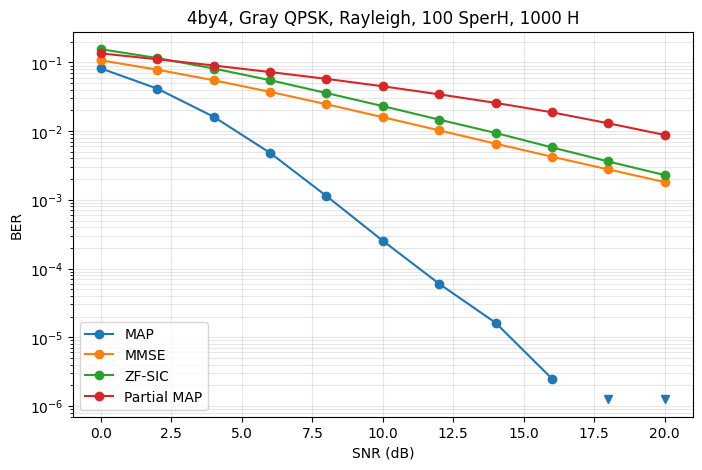

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

snr_db = np.asarray(SNR_DB)
fig, ax = plt.subplots(figsize=(8, 5))

for j, name in enumerate(models):
    points = ber[:, j]
    line, = ax.semilogy(
        snr_db, np.where(points > 0, points, np.nan), "o-", label=name
    )

    zero = points == 0
    if zero.any():
        ax.semilogy(
            snr_db[zero],
            np.full(zero.sum(), 1 / bits_per_snr),
            "v",
            color=line.get_color(),
        )

TITLE = f"{NT}by{NR}, Gray QPSK, Rayleigh, {SYMBOLS_PER_CHANNEL} SperH, {BLOCKS} H"
ax.set(xlabel="SNR (dB)", ylabel="BER",
       title=TITLE)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
print("Downward triangles: zero observed errors, shown at 1 / bits per SNR.")

plt.savefig(f'{TITLE}.png', dpi=300, bbox_inches='tight')
files.download(f'{TITLE}.png')

plt.show()